# Bab 6 — Regresi Logistik Lanjutan dan Pengembangannya

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 6
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_6`)
**Direproduksi dan dijelaskan oleh:** Tarannia Raisha Putri — NIM 101032300231 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 6.1 | Gambaran Regresi Logistik | `LogisticRegression`, `confusion_matrix`, `classification_report` |
| 6.2 | Teknik Klasifikasi Multikelas | One-vs-Rest (`liblinear`) vs multinomial (`lbfgs`) |
| 6.3 | Regularisasi pada Regresi Logistik | `penalty="l1"/"l2"`, `C`, jalur koefisien |
| 6.4 | Konsep Klasifikasi Multilabel | `make_multilabel_classification`, satu model per label |
| 6.5 | Metrik Evaluasi Model | `precision_score`, `recall_score`, `f1_score`, `roc_curve`, `auc` |
| 6.6 | Latihan Praktis Regresi Logistik Lanjutan | model L1, model multinomial, batas keputusan |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 6.6 memakai solusi resmi dari notebook *Exercise Solutions* di repositori.

## Gambaran Umum Bab

Regresi logistik adalah andalan utama untuk klasifikasi. Ia mempertahankan prediktor linear dari Bab 5, $z=\beta_0+\mathbf{x}^\top\boldsymbol\beta$, tetapi melewatkannya ke fungsi sigmoid untuk menghasilkan peluang antara 0 dan 1. Hal ini membuatnya cepat, terkalibrasi dengan baik, dan mudah ditafsirkan: setiap koefisien adalah perubahan **log-odds**.

Bab ini dimulai dengan klasifikasi biner pada dataset Breast Cancer, diperluas ke masalah **multikelas** dengan dua strategi (*one-vs-rest* dan multinomial/softmax), menerapkan **penalti L1 dan L2** dari Bab 5 melalui parameter `C`, beralih ke masalah **multilabel** tempat satu sampel bisa membawa beberapa label sekaligus, dan diakhiri dengan seperangkat **metrik evaluasi** (*precision*, *recall*, F1, kurva ROC, dan AUC). Dalam *pipeline* ML, ini adalah tahap *pemodelan dan evaluasi* untuk klasifikasi. Metrik yang diperkenalkan di sini dipakai ulang untuk setiap *classifier* di Bab 7 dan 8.

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.5
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 6.1 — Gambaran Regresi Logistik

**Tujuan.** Melatih regresi logistik biner yang memprediksi apakah tumor payudara ganas atau jinak dari 30 pengukuran inti sel, lalu mengevaluasinya dengan *confusion matrix* dan metrik per kelas.

### Teori

**Intuisi.** Regresi linear bisa menghasilkan angka berapa pun, padahal peluang harus berada di $[0,1]$. Regresi logistik menghitung skor linear $z$, menafsirkannya sebagai **log-odds**, lalu memampatkannya dengan sigmoid yang berbentuk S. Skor positif besar berarti "hampir pasti kelas 1", skor negatif besar "hampir pasti kelas 0", dan $z=0$ berarti 50/50. Himpunan titik tempat $z=0$ adalah *hyperplane* datar, sehingga batas keputusannya linear.

**Matematika.** Untuk fitur $\mathbf{x}\in\mathbb{R}^p$, koefisien $\boldsymbol\beta$, dan intersep $\beta_0$:
$$z=\beta_0+\mathbf{x}^\top\boldsymbol\beta,\qquad P(y=1\mid\mathbf{x})=\sigma(z)=\frac{1}{1+e^{-z}},\qquad \log\frac{P(y=1\mid\mathbf{x})}{P(y=0\mid\mathbf{x})}=z.$$
Jadi kenaikan satu satuan pada $x_j$ mengalikan odds dengan $e^{\beta_j}$. Parameter di-fit dengan *maximum likelihood*, yaitu dengan meminimalkan **log-loss** (*binary cross-entropy*) $-\sum_i\big[y_i\log p_i+(1-y_i)\log(1-p_i)\big]$ dengan $p_i=\sigma(z_i)$. scikit-learn selalu menambahkan penalti (Resep 6.3). Dengan penalti L2 default dan label yang dikodekan ulang menjadi $y_i\in\{-1,+1\}$, yang diminimalkan adalah
$$\frac12\lVert\boldsymbol\beta\rVert_2^2+C\sum_{i=1}^{n}\log\big(1+e^{-y_i z_i}\big),$$
dengan $C>0$ adalah **kebalikan** dari kekuatan regularisasi. Prediksinya kelas 1 ketika $\sigma(z)\ge0.5$, yaitu ketika $z\ge0$.

**Cara scikit-learn mengimplementasikannya.** `LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", max_iter=100, tol=1e-4, class_weight=None)`.

* `fit` meminimalkan fungsi objektif di atas dengan solver iteratif. Default `lbfgs` adalah metode quasi-Newton. Alternatifnya `liblinear`, `newton-cg`, `newton-cholesky`, `sag`, dan `saga`, yang berbeda dalam kecepatan dan penalti yang didukung.
* `predict_proba` mengembalikan $[1-\sigma(z),\ \sigma(z)]$, `decision_function` mengembalikan $z$, dan `predict` memakai ambang 0,5.
* `coef_` / `intercept_` menyimpan $\boldsymbol\beta$ / $\beta_0$. `n_iter_` melaporkan jumlah iterasi solver yang dibutuhkan.
* Solver berbasis gradien konvergen lambat ketika skala fitur sangat berbeda. Pada data yang tidak diskalakan, solver bisa berhenti di `max_iter` dengan `ConvergenceWarning`, itulah sebabnya resep ini menaikkan `max_iter` menjadi 10.000.

**Asumsi, kelebihan, keterbatasan.**

* Mengasumsikan log-odds linear terhadap fitur dan observasi saling independen. Fitur yang sangat kolinear membuat koefisien individual tidak stabil, meskipun prediksinya mungkin tetap baik.
* Kelebihan: output probabilistik, cepat, mudah ditafsirkan (*odds ratio*), *baseline* yang kuat.
* Keterbatasan: batas keputusan linear (efek non-linear memerlukan rekayasa fitur), sensitif terhadap skala fitur untuk konvergensi dan penalti, dan bisa terlalu yakin ketika kelas terpisah sempurna (penalti mencegah koefisien tak hingga).

### Kode

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Breast Cancer Wisconsin: 569 tumor, 30 fitur; 0 = ganas (malignant), 1 = jinak (benign)
data = load_breast_cancer()
X = data.data
y = data.target

# Tampilan DataFrame dengan kolom target
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

# Pembagian 80/20 -> 455 tumor latih / 114 tumor uji
X_train, X_test, y_train, y_test = train_test_split(df[data.feature_names],
                                                    df['target'],
                                                    test_size=0.2,
                                                    random_state=2024)

In [3]:
# Fitur tidak diskalakan, jadi beri solver lbfgs banyak iterasi
model = LogisticRegression(max_iter=10000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

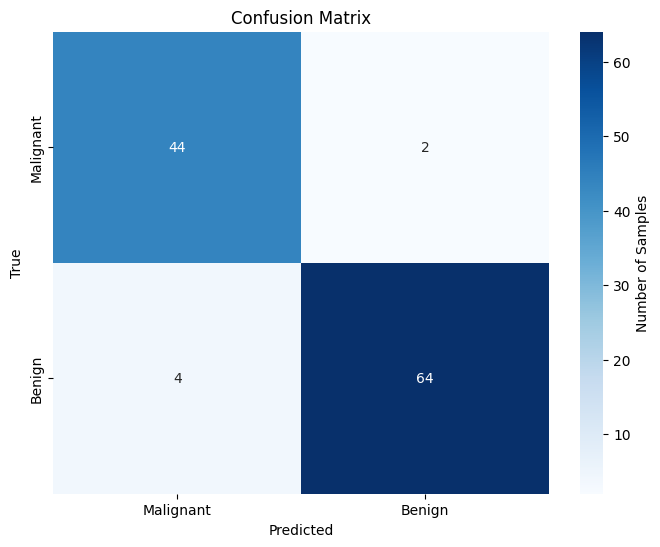

In [4]:
# Confusion matrix sebagai heatmap beranotasi
class_names = ['Malignant', 'Benign']
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

**Interpretasi output.** Dari 114 tumor uji, **44 ganas** dan **64 jinak** diklasifikasikan dengan benar. Ada **2 *false negative* dalam arti klinis** (tumor ganas yang diprediksi jinak, sel kanan atas) dan **4 tumor jinak yang ditandai ganas** (kiri bawah). Dalam konteks skrining, kesalahan jenis pertama adalah yang mahal, karena kanker yang terlewat jauh lebih berbahaya daripada pemeriksaan lanjutan yang tidak perlu.

In [5]:
# Precision / recall / F1 per kelas sebagai tabel bergaya
report_dict = classification_report(y_test, y_pred,
                                  target_names=class_names,
                                  output_dict=True)

report_df = pd.DataFrame(report_dict).transpose()

styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f'Accuracy: {accuracy:.2f}\n')
print("\nClassification Report:")
display(styled_df)

Accuracy: 0.95


Classification Report:


,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


In [6]:
# Seberapa keras solver bekerja pada data yang tidak diskalakan? (tambahan)
print("iterasi lbfgs yang dipakai:", model.n_iter_[0], "(max_iter default 100)")
print("jumlah per kelas di seluruh dataset:", {str(n): int(c) for n, c in zip(data.target_names, np.bincount(y))})

iterasi lbfgs yang dipakai: 2004 (max_iter default 100)
jumlah per kelas di seluruh dataset: {'malignant': 212, 'benign': 357}


**Interpretasi output.**

* **Akurasi 0.95** (lebih tepatnya 0.947 = 108/114).
* **Ganas (malignant):** *recall* **0.957** (44 dari 46 ditemukan) dan *precision* **0.917** (44 dari 48 tumor yang diprediksi ganas memang ganas).
* **Jinak (benign):** *precision* **0.970**, *recall* **0.941**.
* *Weighted average* (≈ 0.948) dekat dengan *macro average* (≈ 0.946), karena data uji hanya sedikit tidak seimbang (46 vs 68). Seluruh dataset berisi 212 tumor ganas dan 357 tumor jinak.
* Baris `accuracy` mengulang satu angka di semua kolom, dan `support`-nya menampilkan "1". Itu artefak format saat dictionary laporan diubah menjadi DataFrame, seperti dijelaskan di Bab 4.
* Pengecekan tambahan menunjukkan solver membutuhkan **lebih dari 2.000 iterasi**. Jumlah tepatnya sedikit berubah dari satu eksekusi ke eksekusi lain (kira-kira antara 2.000 dan 4.000 dalam eksekusi saya) karena galat pembulatan *floating-point* pada aljabar linear *multithreaded* memengaruhi masalah yang terkondisi buruk seperti ini, tetapi prediksi dan akurasinya tidak berubah. Dengan `max_iter=100` default, solver akan berhenti terlalu dini dengan `ConvergenceWarning`, karena fitur yang tidak diskalakan berkisar dari sekitar 0,001 hingga beberapa ribu. Menskalakan fitur (seperti di Resep 6.3) menyelesaikan masalah ini dengan benar.

### Poin Penting
* Regresi logistik memodelkan log-odds secara linear dan memetakannya menjadi peluang dengan sigmoid. Batasnya adalah *hyperplane* $z=0$.
* Pada Breast Cancer, akurasinya 94,7 %, dengan 2 dari 46 tumor ganas terlewat.
* Fitur yang tidak diskalakan membuat solver lambat (lebih dari 2.000 iterasi lbfgs di sini). Standardisasi sebelum fitting.
* Perhatikan *recall* dan *precision* per kelas, karena kedua jenis kesalahan jarang memiliki biaya yang sama.

## Resep 6.2 — Teknik Klasifikasi Multikelas

**Tujuan.** Memperluas regresi logistik dari dua kelas menjadi tiga (spesies Iris) dengan dua strategi, *one-vs-rest* dan multinomial (softmax), lalu membandingkan prediksinya.

### Teori

**Intuisi.** *Classifier* biner menjawab "A atau bukan A". Dengan $K$ kelas ada dua perluasan alami. **One-vs-Rest (OvR)** melatih $K$ model biner terpisah ("setosa vs lainnya", "versicolor vs lainnya", "virginica vs lainnya") dan memilih yang paling yakin. **Regresi multinomial (softmax)** melatih satu model gabungan yang $K$ skornya bersaing secara langsung, sehingga peluang dipelajari bersama dan secara konstruksi berjumlah satu.

**Matematika.**

* **OvR:** untuk setiap kelas $k$, fit $P_k(\mathbf{x})=\sigma(\beta_{0k}+\mathbf{x}^\top\boldsymbol\beta_k)$ pada label $\mathbb{1}[y=k]$, dan prediksi $\hat y=\arg\max_k P_k(\mathbf{x})$. Ke-$K$ model dilatih secara independen, dan scikit-learn menormalisasi outputnya agar setiap baris `predict_proba` berjumlah 1.
* **Multinomial:** dengan skor $z_k=\beta_{0k}+\mathbf{x}^\top\boldsymbol\beta_k$,
$$P(y=k\mid\mathbf{x})=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}\quad(\text{softmax}),$$
dan semua $\boldsymbol\beta_k$ di-fit bersama dengan meminimalkan *cross-entropy* multikelas $-\sum_i\log P(y_i\mid\mathbf{x}_i)$ (ditambah penalti).

**Cara scikit-learn mengimplementasikannya.** Di scikit-learn 1.5, strateginya mengikuti solver. `solver="liblinear"` hanya mendukung masalah biner, sehingga untuk $K>2$ ia otomatis mem-fit $K$ model *one-vs-rest*. `solver="lbfgs"` (default) mem-fit model multinomial. Dalam kedua kasus, `coef_` berbentuk $(K, p)$. Argumen lama `multi_class` sudah *deprecated* sejak v1.5, dan cara eksplisit yang dianjurkan untuk mendapatkan OvR dengan solver apa pun adalah `sklearn.multiclass.OneVsRestClassifier(LogisticRegression())`.

**Asumsi, kelebihan, keterbatasan.**

* OvR: sederhana dan dapat diparalelkan, tetapi setiap masalah biner tidak seimbang (satu kelas vs semua lainnya) dan skor yang dilatih secara independen tidak terkalibrasi satu sama lain.
* Multinomial: satu model probabilistik yang koheren, biasanya lebih terkalibrasi, dan menjadi pilihan standar untuk kelas yang saling eksklusif.
* Keduanya menghasilkan batas linear antarkelas, dan pada dataset kecil akurasinya sering mirip.

### Kode

In [7]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import DecisionBoundaryDisplay
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Iris: 150 bunga, 4 fitur, 3 spesies
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Pembagian 70/30 -> 105 bunga latih / 45 bunga uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [8]:
# liblinear menangani multikelas lewat one-vs-rest (3 model biner)
ovr_model = LogisticRegression(solver='liblinear')
ovr_model.fit(X_train, y_train)

# lbfgs mem-fit satu model multinomial (softmax)
multinomial_model = LogisticRegression(solver='lbfgs', max_iter = 1000)
multinomial_model.fit(X_train, y_train)

y_pred_ovr = ovr_model.predict(X_test)

y_pred_multinomial = multinomial_model.predict(X_test)

In [9]:
# One-vs-rest: akurasi dan laporan per kelas bergaya
accuracy_ovr = accuracy_score(y_test, y_pred_ovr)
report_ovr = pd.DataFrame(classification_report(y_test, y_pred_ovr, output_dict=True)).transpose()
print("One-vs-Rest (OvR) Logistic Regression:")

styled_ovr = (report_ovr
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovr)

One-vs-Rest (OvR) Logistic Regression:


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.917,0.917,0.917,12
2,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


In [10]:
# Multinomial: akurasi dan laporan per kelas bergaya
accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
report_multinomial = pd.DataFrame(classification_report(y_test, y_pred_multinomial, output_dict=True)).transpose()
print("Multinomial Logistic Regression:")

styled_multinomial = (report_multinomial
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_multinomial)

Multinomial Logistic Regression:


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.846,0.917,0.880,12
2,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


In [11]:
from sklearn.metrics import confusion_matrix

# Di mana tepatnya kedua strategi berbeda? (tambahan)
diff = np.flatnonzero(y_pred_ovr != y_pred_multinomial)
print("bentuk coef_:", ovr_model.coef_.shape, multinomial_model.coef_.shape)
print("sampel uji dengan prediksi berbeda:", diff, "| label sebenarnya:", y_test[diff],
      "| OvR:", y_pred_ovr[diff], "| multinomial:", y_pred_multinomial[diff])
print("Confusion matrix OvR:\n", confusion_matrix(y_test, y_pred_ovr))
print("Confusion matrix multinomial:\n", confusion_matrix(y_test, y_pred_multinomial))

bentuk coef_: (3, 4) (3, 4)
sampel uji dengan prediksi berbeda: [ 3 17 38] | label sebenarnya: [2 2 2] | OvR: [2 2 1] | multinomial: [1 1 2]
Confusion matrix OvR:
 [[18  0  0]
 [ 0 11  1]
 [ 0  1 14]]
Confusion matrix multinomial:
 [[18  0  0]
 [ 0 11  1]
 [ 0  2 13]]


**Interpretasi output.**

* **OvR: akurasi 0.956** (43/45). **Multinomial: 0.933** (42/45).
* Keduanya mengklasifikasikan ke-**18 setosa** dengan sempurna (*precision* = *recall* = 1.000).
* Kesalahan hanya melibatkan versicolor (1) dan virginica (2). OvR membuat satu kesalahan ke masing-masing arah (F1 versicolor 0.917, virginica 0.933). Multinomial membuat satu kesalahan versicolor→virginica dan dua kesalahan virginica→versicolor (*recall* virginica 0.867).
* Pengecekan tambahan menunjukkan kedua model berbeda pendapat pada tepat **tiga bunga virginica di data uji**: OvR benar pada dua di antaranya, multinomial pada satu.
* Kedua model memiliki `coef_` berbentuk (3, 4), satu vektor bobot per kelas.
* Selisih satu bunga dari 45 sampel uji masih dalam batas *noise*, jadi ini bukan bukti bahwa OvR secara umum lebih baik.

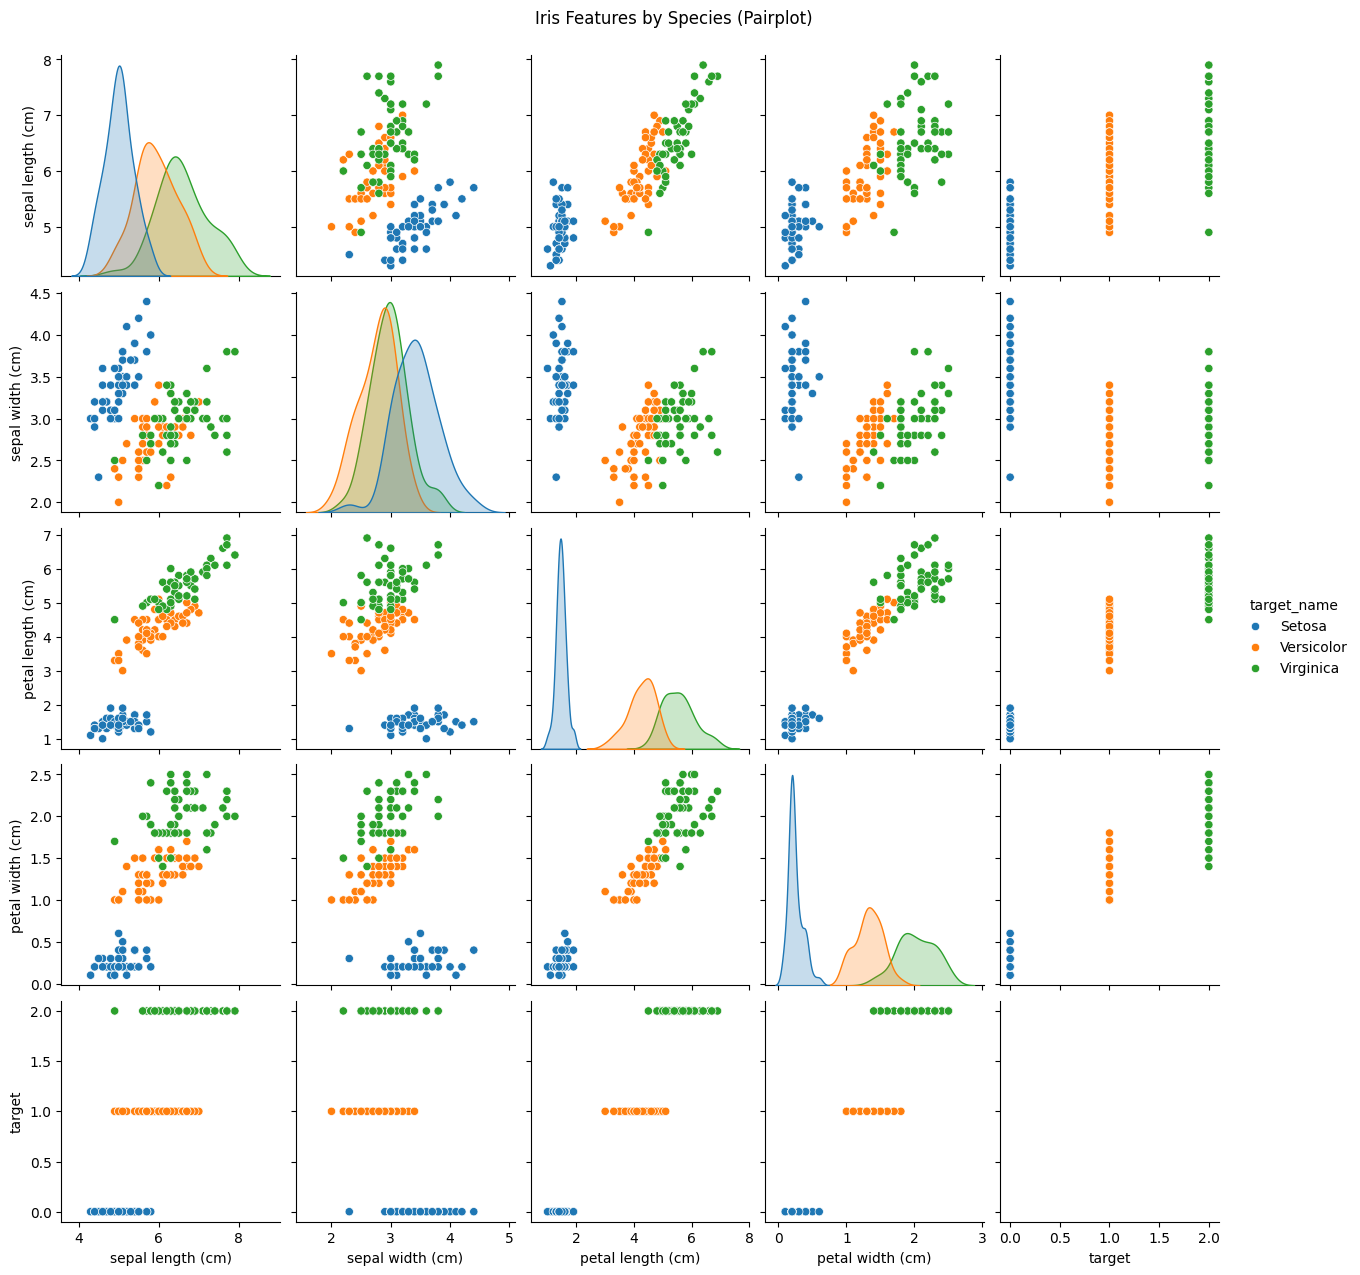

In [12]:
# Scatter plot berpasangan untuk semua kolom numerik, diwarnai per spesies
target_names = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
df['target_name'] = df['target'].map(target_names)
sns.pairplot(df, hue='target_name', diag_kind='kde')
plt.suptitle('Iris Features by Species (Pairplot)', y=1.02)  # (tambahan)
plt.show()

> **Catatan:** Baris `plt.suptitle(...)` yang ditandai `# (tambahan)` tidak ada di buku. Baris ini hanya memberi judul pada gambar, sesuai ketentuan bahwa setiap plot di repositori ini harus berjudul.

**Interpretasi output.** *Pairplot* menjelaskan hasil di atas. Di setiap panel yang melibatkan **petal length** atau **petal width**, setosa (biru) membentuk klaster terpisah yang jauh dari yang lain. Itulah sebabnya kedua model mengklasifikasikannya dengan sempurna. Versicolor (oranye) dan virginica (hijau) bertumpang tindih, paling terlihat di panel sepal dan sedikit di tepi panel petal, dan dari situlah semua kesalahan klasifikasi berasal. Plot KDE di diagonal menunjukkan petal length dan width sebagai fitur tunggal yang paling membedakan. Karena buku mengirimkan seluruh DataFrame, kolom numerik `target` juga muncul sebagai "fitur" kelima (baris bawah dan kolom kanan). Panel-panel itu hanya menampilkan setiap spesies pada nilai konstannya sendiri.

### Poin Penting
* OvR melatih $K$ model biner independen, sedangkan regresi multinomial (softmax) melatih satu model gabungan dengan peluang yang berjumlah 1.
* Di scikit-learn 1.5, `liblinear` → OvR dan `lbfgs` → multinomial.
* Pada Iris keduanya mencapai sekitar 93–96 %. Satu-satunya kekeliruan adalah versicolor ↔ virginica, yang bertumpang tindih di ruang fitur.

## Resep 6.3 — Regularisasi pada Regresi Logistik

**Tujuan.** Menerapkan penalti L2 (ridge) dan L1 (lasso) pada regresi logistik dengan data Breast Cancer yang terstandardisasi, membandingkan akurasinya pada $C=0.1$, dan memvisualisasikan perubahan koefisien ketika $C$ divariasikan sepanjang delapan orde besaran.

### Teori

**Intuisi.** Penalti dari Bab 5 bekerja dengan cara yang sama untuk klasifikasi. Penalti mencegah koefisien yang besar agar model tidak *overfit* terhadap *noise* di data latih. L2 mengecilkan semua koefisien secara halus. L1 mendorong banyak koefisien menjadi tepat nol, sehingga melakukan seleksi fitur. Perbedaannya dengan Bab 5 adalah *kenop*-nya: `LogisticRegression` di scikit-learn memakai $C$, yaitu **kebalikan** dari kekuatan penalti. **$C$ kecil = regularisasi kuat, $C$ besar = regularisasi lemah.**

**Matematika.** Dengan label $y_i\in\{-1,+1\}$ dan $z_i=\beta_0+\mathbf{x}_i^\top\boldsymbol\beta$:
$$\text{L2: }\min_{\boldsymbol\beta,\beta_0}\ \frac12\lVert\boldsymbol\beta\rVert_2^2+C\sum_{i}\log\big(1+e^{-y_iz_i}\big),\qquad \text{L1: }\min_{\boldsymbol\beta,\beta_0}\ \lVert\boldsymbol\beta\rVert_1+C\sum_{i}\log\big(1+e^{-y_iz_i}\big).$$
Membagi dengan $C$ menunjukkan kesetaraannya dengan Bab 5: $C$ berperan sebagai $1/\alpha$. Ketika $C\to0$ semua koefisien menuju 0 (model hanya memprediksi dari intersep), dan ketika $C\to\infty$ kita mendekati fit *maximum likelihood* tanpa penalti.

**Cara scikit-learn mengimplementasikannya.** `LogisticRegression(penalty=..., C=..., solver=...)`. Tidak setiap solver mendukung setiap penalti: `lbfgs`, `newton-cg`, `newton-cholesky`, dan `sag` hanya mendukung L2 (atau tanpa penalti). `liblinear` mendukung L1 dan L2. `saga` mendukung L1, L2, dan ElasticNet. Karena itu resep ini memakai `solver="liblinear"` untuk kedua penalti. Perhatikan bahwa liblinear juga memberi sedikit penalti pada intersep. Koefisien dapat dibandingkan antarfitur hanya karena data telah distandardisasi dengan `StandardScaler` (di-fit hanya pada bagian data latih).

**Asumsi, kelebihan, keterbatasan.**

* Pilih $C$ dengan *cross-validation* (misalnya `LogisticRegressionCV`). Nilai terbaik bergantung pada ukuran sampel dan *noise*.
* L1 menghasilkan model yang *sparse* dan mudah ditafsirkan, tetapi di antara fitur yang berkorelasi (data Breast Cancer memiliki banyak, misalnya radius/perimeter/area) ia mempertahankan satu secara agak sembarang. L2 menyebarkan bobot ke semuanya.
* Penalti bergantung pada skala, sehingga standardisasi lebih dulu sangat penting.

### Kode

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Pembagian 70/30 -> 398 tumor latih / 171 tumor uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Standardisasi dengan statistik dari bagian data latih saja
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [14]:
# C = 0.1 yang sama (penalti cukup kuat) untuk kedua jenis penalti
ridge_model = LogisticRegression(penalty='l2', solver='liblinear', C=0.1)
ridge_model.fit(X_train, y_train)

lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.1)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)

y_pred_lasso = lasso_model.predict(X_test)

In [15]:
# Model L2: akurasi dan laporan bergaya
accuracy_ridge = accuracy_score(y_test, y_pred_ridge)
report_ridge = pd.DataFrame(classification_report(y_test, y_pred_ridge, output_dict=True)).transpose()
print("Ridge (L2) Regularized Logistic Regression:")

styled_ridge = (report_ridge
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ridge)

Ridge (L2) Regularized Logistic Regression:


,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


In [16]:
# Model L1: akurasi dan laporan bergaya
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
report_lasso = pd.DataFrame(classification_report(y_test, y_pred_lasso, output_dict=True)).transpose()
print("Lasso (L1) Regularized Logistic Regression:")

styled_lasso = (report_lasso
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_lasso)

Lasso (L1) Regularized Logistic Regression:


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171


In [17]:
# Tingkat sparsity kedua model C = 0.1 (tambahan; harus dijalankan sebelum loop C di bawah memakai ulang nama-nama ini)
nz = lasso_model.coef_[0] != 0
print("koefisien tak-nol -> L2:", int((ridge_model.coef_[0] != 0).sum()), "dari 30 | L1:", int(nz.sum()), "dari 30")
pd.Series(lasso_model.coef_[0][nz], index=feature_names[nz], name="koefisien L1 (C=0.1)").round(3).sort_values()

koefisien tak-nol -> L2: 30 dari 30 | L1: 7 dari 30


worst radius           -1.845
mean concave points    -0.993
worst concave points   -0.825
worst texture          -0.620
worst symmetry         -0.154
worst smoothness       -0.041
worst concavity        -0.022
Name: koefisien L1 (C=0.1), dtype: float64

**Interpretasi output.**

* Dengan $C=0.1$ yang sama, **model L2 mencapai akurasi 0.982** (168/171) dan **model L1 0.965** (165/171).
* L2 mempertahankan profil yang seimbang: *recall* ganas (kelas 0) 0.970, *recall* jinak 0.990. Model L1 menukar *recall* jinak (0.952) dengan *recall* ganas yang lebih tinggi (0.985).
* Pengecekan tambahan menunjukkan apa yang diperoleh L1: **hanya 7 dari 30 koefisien yang tidak nol**, dibanding ke-30 untuk L2. Fitur yang bertahan sebagian besar adalah pengukuran "worst" (nilai terbesar): `worst radius` (−1.845), `mean concave points` (−0.993), `worst concave points` (−0.825), `worst texture` (−0.620), dan tiga koefisien kecil.
* Semua tandanya negatif karena kelas positifnya adalah *jinak*: inti sel yang lebih besar dan lebih tidak beraturan menurunkan odds untuk jinak.
* Model 7 fitur yang akurasinya hanya 1,7 poin lebih rendah menarik ketika kemudahan tafsir atau biaya pengukuran penting.

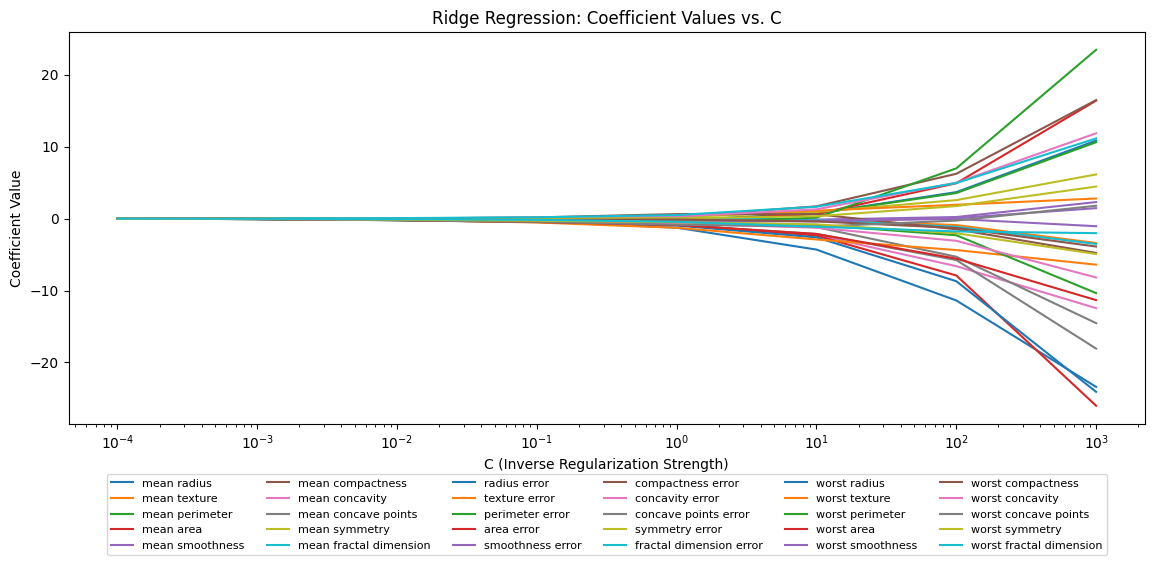

In [18]:
# Jalur koefisien L2 untuk C = 1e-4 ... 1e3
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_ridge = []

for C in C_values:
    ridge_model = LogisticRegression(penalty='l2', solver='liblinear', C=C)
    ridge_model.fit(X_train, y_train)
    coefs_ridge.append(ridge_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_ridge], label=feature_names[i])
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Ridge Regression: Coefficient Values vs. C')
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()

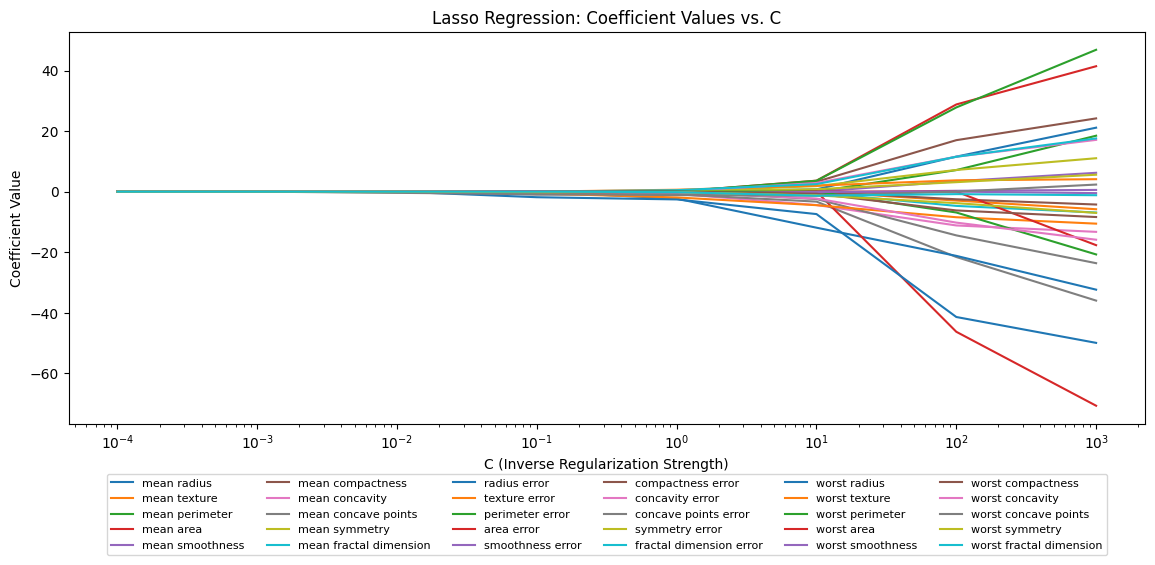

In [19]:
# Jalur koefisien L1 pada grid C yang sama
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_lasso = []

for C in C_values:
    lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=C)
    lasso_model.fit(X_train, y_train)
    coefs_lasso.append(lasso_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_lasso], label=feature_names[i])
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Lasso Regression: Coefficient Values vs. C')
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()

In [20]:
# Jumlah koefisien L1 tak-nol dan |koefisien L2| terbesar untuk setiap C (tambahan)
pd.DataFrame({
    "C": C_values,
    "koef L1 tak-nol": [int((c != 0).sum()) for c in coefs_lasso],
    "|koef| L2 maks": [round(float(np.abs(c).max()), 3) for c in coefs_ridge],
}).set_index("C").T

C,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000,1000.0000
koef L1 tak-nol,0.000,0.000,2.000,7.000,15.000,23.000,27.000,30.000
|koef| L2 maks,0.014,0.077,0.234,0.546,1.287,4.313,11.383,26.009


**Interpretasi output.** (Buku memberi judul plot ini "Ridge/Lasso Regression", padahal modelnya adalah regresi *logistik* berpenalti L2/L1.)

* **Jalur L2:** untuk $C\le10^{-2}$ setiap koefisien ditekan mendekati 0 (|koefisien| terbesar hanya 0.014 pada $C=10^{-4}$). Seiring bertambahnya $C$, jalur-jalur menyebar secara halus, dan pada $C=1000$ koefisien tersebar antara sekitar −26 dan +23. Bobot sebesar itu pada fitur terstandardisasi menandakan model mendekati solusi tanpa regularisasi yang *overfit*. Banyaknya garis yang bersilangan mencerminkan kolinearitas kuat di antara fitur-fitur ukuran.
* **Jalur L1:** pada $C=10^{-4}$ dan $10^{-3}$, **ke-30 koefisien tepat 0**. Tabel tambahan menunjukkan fitur masuk satu per satu seiring melemahnya penalti: 2 pada $C=0.01$, 7 pada $0.1$, 15 pada $1$, 23 pada $10$, dan ke-30 pada $C=1000$. Begitu hampir tanpa penalti, koefisien L1 menjadi lebih ekstrem daripada L2 (hingga sekitar −70), karena tidak ada yang mencegah fitur-fitur berkorelasi mengambil bobot besar yang saling meniadakan.
* Kedua plot menunjukkan pelajaran yang sama dengan jalur koefisien di Bab 5: kekuatan regularisasi menggeser model dari "terlalu sederhana" (semua nol) ke "terlalu fleksibel" (bobot besar dan tidak stabil).

### Poin Penting
* Pada `LogisticRegression`, `C` adalah kebalikan kekuatan penalti: $C$ kecil = regularisasi kuat.
* Pada $C=0.1$, L2 memberi akurasi terbaik (0.982), sedangkan L1 mencapai 0.965 dengan hanya 7 dari 30 fitur.
* Jalur L1 menunjukkan fitur masuk satu per satu seiring bertambahnya $C$ (0 → 2 → 7 → 15 → 23 → 30). Jalur L2 mengecil secara halus dan tidak pernah mencapai nol tepat.
* Hanya `liblinear` dan `saga` yang mendukung penalti L1.

## Resep 6.4 — Konsep Klasifikasi Multilabel

**Tujuan.** Menangani masalah ketika setiap sampel dapat membawa *beberapa* label sekaligus (misalnya film yang sekaligus "komedi" dan "romantis"), dengan melatih satu regresi logistik biner per label, lalu menganalisis seberapa sering label-label muncul bersamaan.

### Teori

**Intuisi.** Pada masalah multikelas, setiap sampel memiliki tepat satu dari $K$ label. Pada masalah **multilabel**, setiap sampel memiliki *himpunan* label, yang dinyatakan sebagai vektor biner $\mathbf{y}\in\{0,1\}^L$. Pendekatan paling sederhana, **binary relevance**, memperlakukan setiap dari $L$ label sebagai masalah ya/tidak tersendiri dan melatih $L$ *classifier* independen. Pendekatan ini mudah dan skalabel, tetapi mengabaikan korelasi antarlabel (jika "label 2" hampir selalu muncul bersama "label 0", model tidak memanfaatkan fakta itu).

**Matematika.** *Binary relevance* mem-fit, untuk setiap label $\ell=1,\dots,L$, $P(y_\ell=1\mid\mathbf{x})=\sigma(\beta_{0\ell}+\mathbf{x}^\top\boldsymbol\beta_\ell)$, dan memprediksi $\hat y_\ell=\mathbb{1}[P(y_\ell=1\mid\mathbf{x})\ge0.5]$. Evaluasi multilabel membutuhkan metriknya sendiri:

* **Subset accuracy:** $\frac1n\sum_i\mathbb{1}[\hat{\mathbf{y}}_i=\mathbf{y}_i]$, yaitu seluruh vektor label harus tepat benar. Metrik ini sangat ketat.
* **Hamming loss:** $\frac{1}{nL}\sum_i\sum_\ell\mathbb{1}[\hat y_{i\ell}\ne y_{i\ell}]$, proporsi keputusan label individual yang salah.
* *Precision/recall/F1* per label beserta rata-ratanya. **Micro** menggabungkan semua keputusan label, **macro** merata-ratakan skor per label secara setara, **weighted** merata-ratakan berdasarkan *support* label, dan **samples** menghitung metrik per sampel lalu merata-ratakannya.
* **Matriks ko-okurensi:** $M=Y^\top Y$, dengan $M_{jk}$ menghitung sampel yang memiliki label $j$ dan $k$ sekaligus (diagonal memuat frekuensi label). Membagi baris $j$ dengan $M_{jj}$ menghasilkan frekuensi bersyarat $P(\text{label }k\mid\text{label }j)$.

**Cara scikit-learn mengimplementasikannya.** `make_multilabel_classification(n_samples, n_features, n_classes, n_labels=2, allow_unlabeled=True)` mengambil jumlah label per sampel dari distribusi Poisson dengan rata-rata `n_labels`, sehingga **beberapa sampel bisa tidak memiliki label sama sekali**. `y` adalah matriks indikator berbentuk `(n_samples, n_classes)`. Resep ini melakukan perulangan atas kolom secara manual. Hal yang sama tersedia sebagai `sklearn.multiclass.OneVsRestClassifier` atau `sklearn.multioutput.MultiOutputClassifier`, dan `ClassifierChain` menambahkan ketergantungan antarlabel. `accuracy_score` pada matriks indikator menghitung *subset accuracy*, dan `classification_report` menerimanya secara langsung. `zero_division=1` menetapkan *precision* menjadi 1 ketika suatu label (atau sampel) tidak memiliki prediksi positif, yang dapat membuat rata-rata terlihat lebih baik daripada kenyataannya.

**Asumsi, kelebihan, keterbatasan.**

* *Binary relevance* mengasumsikan label independen secara bersyarat jika diketahui $\mathbf{x}$. Label yang jarang menghasilkan masalah biner yang sangat tidak seimbang dan sering kurang diprediksi.
* Ambang 0,5 per label jarang optimal. Men-*tuning* ambang per label atau memakai `class_weight` dapat menaikkan *recall* pada label yang jarang.

### Kode

In [21]:
from sklearn.datasets import make_multilabel_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1.000 sampel, 20 fitur mirip cacahan, 5 label yang mungkin (rata-rata ~2 per sampel)
X, y = make_multilabel_classification(n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024)
df = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(X.shape[1])])
df['target'] = list(y)

# Pembagian 70/30 -> 700 sampel latih / 300 sampel uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [22]:
# Binary relevance: satu regresi logistik independen per kolom label
models = []
y_pred_all = []

for i in range(y_train.shape[1]):
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train, y_train[:, i])
    models.append(model)

    y_pred_label = model.predict(X_test)
    y_pred_all.append(y_pred_label)

# Tumpuk prediksi per label kembali menjadi matriks (n_samples, n_labels)
y_pred = np.array(y_pred_all).T

# accuracy_score pada matriks indikator = subset accuracy (harus tepat sama)
accuracy = accuracy_score(y_test, y_pred)
report = pd.DataFrame(classification_report(y_test, y_pred, zero_division=1, output_dict=True)).transpose()
print("Classification Report:")

styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

Classification Report:


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


In [23]:
from sklearn.metrics import hamming_loss

# Buku menghitung `accuracy` (subset accuracy) tetapi tidak pernah mencetaknya (tambahan)
print(f"subset accuracy (tepat sama)     : {accuracy:.3f}")
print(f"Hamming loss                     : {hamming_loss(y_test, y_pred):.3f}")
print(f"rata-rata label asli per sampel  : {y_test.sum(axis=1).mean():.2f} | rata-rata prediksi: {y_pred.sum(axis=1).mean():.2f}")

subset accuracy (tepat sama)     : 0.340
Hamming loss                     : 0.209
rata-rata label asli per sampel  : 1.87 | rata-rata prediksi: 1.62


**Interpretasi output.**

* **Per label:** label 0 dan 1 (yang paling sering) diprediksi dengan baik (F1 0.811 dan 0.823). Label 2 memiliki *precision* yang lumayan (0.674) tetapi hanya menemukan sepertiga positifnya (*recall* 0.333). **Label 3**, yang paling jarang dengan 34 positif di data uji, hampir tidak pernah diprediksi: *recall* **0.176**, F1 0.286. Inilah kelemahan khas *binary relevance* pada label yang jarang.
* **Rata-rata:** F1 micro **0.701**, sedangkan F1 macro hanya 0.577 karena memberi bobot setara pada label jarang yang prediksinya buruk.
* **Pengecekan tambahan:** *subset accuracy* yang ketat **hanya 0.340**. Hanya sepertiga dari 300 sampel yang seluruh himpunan labelnya tepat benar. **Hamming loss 0.209** berarti sekitar satu dari lima keputusan ya/tidak per label salah.
* Model memprediksi sedikit lebih sedikit label per sampel (1.62) daripada yang sebenarnya (1.87), sesuai dengan *recall* yang rendah pada label 2–4. *Precision* "samples avg" (0.787) sebagian digelembungkan oleh `zero_division=1`, yang menghitung sampel tanpa label prediksi sebagai sempurna *precision*-nya.


Label Statistics:
Total samples: 300

Label frequencies:
Label 0: 166 samples (55.3%)
Label 1: 181 samples (60.3%)
Label 2: 93 samples (31.0%)
Label 3: 34 samples (11.3%)
Label 4: 88 samples (29.3%)

Most common label combinations:
Combination [0 0 0 0 0]: 52 samples (17.3%)
Combination [0 1 0 0 0]: 34 samples (11.3%)
Combination [1 1 0 0 0]: 28 samples (9.3%)
Combination [1 1 1 0 0]: 25 samples (8.3%)
Combination [1 1 0 0 1]: 24 samples (8.0%)


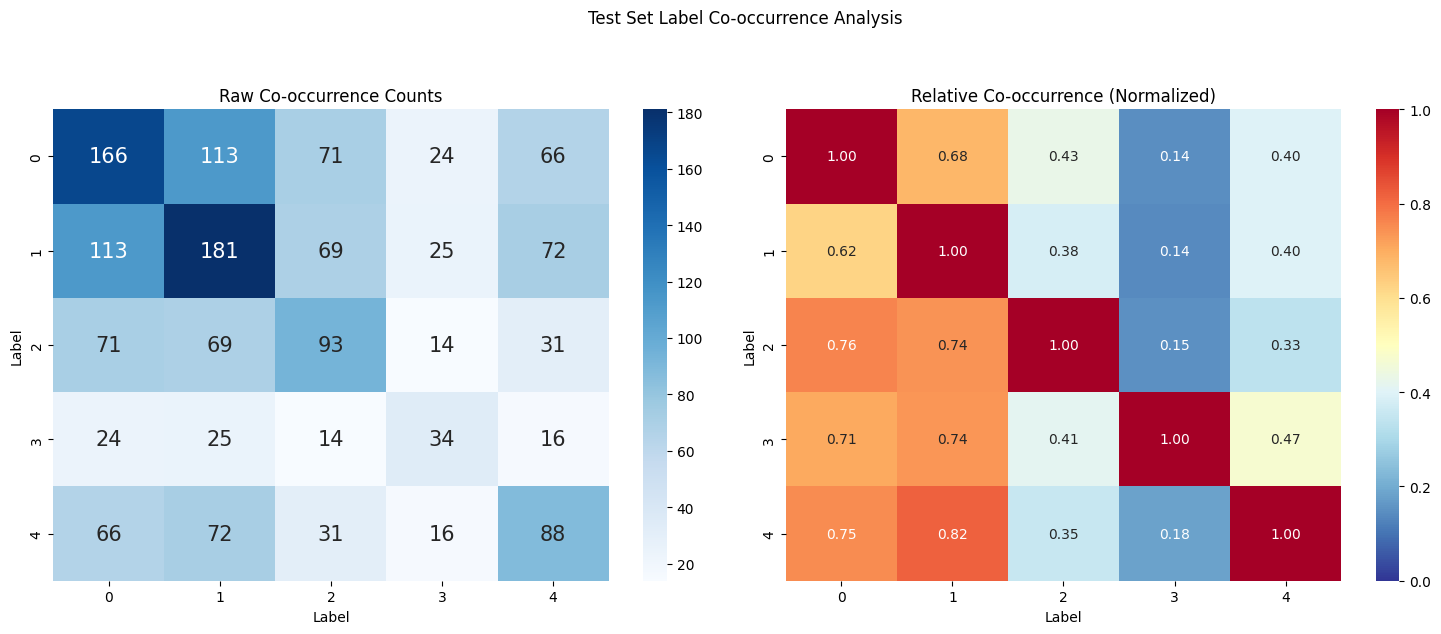

In [24]:
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    # Cacahan mentah: entri (i, j) = jumlah sampel yang memiliki label i dan label j
    cooccurrence = y.T @ y

    # Normalisasi baris dengan diagonal: porsi sampel berlabel i yang juga membawa label j
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues',
                ax=ax1, annot_kws={"fontsize": 15})
    ax1.set_title('Raw Co-occurrence Counts')
    ax1.set_xlabel('Label')
    ax1.set_ylabel('Label')

    sns.heatmap(relative_cooccurrence, annot=True, fmt='.2f',
                cmap='RdYlBu_r', ax=ax2, annot_kws={"fontsize": 10},
                vmin=0, vmax=1)
    ax2.set_title('Relative Co-occurrence (Normalized)')
    ax2.set_xlabel('Label')
    ax2.set_ylabel('Label')

    plt.suptitle(title, y=1.05)
    plt.tight_layout()

    # Ringkasan teks: frekuensi label dan himpunan label yang paling umum
    print("\nLabel Statistics:")
    print(f"Total samples: {len(y)}")
    print("\nLabel frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        percentage = count / len(y) * 100
        print(f"Label {i}: {count} samples ({percentage:.1f}%)")

    print("\nMost common label combinations:")
    unique_combinations = np.unique(y, axis=0, return_counts=True)
    sorted_idx = np.argsort(-unique_combinations[1])
    for combo, count in zip(unique_combinations[0][sorted_idx][:5],
                          unique_combinations[1][sorted_idx][:5]):
        percentage = count / len(y) * 100
        print(f"Combination {combo}: {count} samples ({percentage:.1f}%)")

# Analisis label asli pada data uji
plot_label_cooccurrence(y_test, "Test Set Label Co-occurrence Analysis")

**Interpretasi output.**

* **Frekuensi:** pada 300 sampel uji, label 1 muncul di 60,3 % dan label 0 di 55,3 %, sedangkan label 3 hanya di 11,3 % (34 sampel). Ketidakseimbangan itu menjelaskan *recall* label 3 yang buruk di atas.
* **Kombinasi:** "kombinasi" yang paling umum adalah **tanpa label sama sekali** (`[0 0 0 0 0]`, 52 sampel, 17,3 %), konsekuensi dari `allow_unlabeled=True`. Berikutnya label 1 saja (11,3 %), label {0, 1} (9,3 %), {0, 1, 2} (8,3 %), dan {0, 1, 4} (8,0 %).
* **Cacahan mentah (heatmap kiri):** diagonal mengulang frekuensi label (166, 181, 93, 34, 88), dan label 0 dan 1 muncul bersamaan 113 kali.
* **Ko-okurensi relatif (heatmap kanan, baris = "jika diketahui label i"):** label-label sangat saling bergantung. Jika ada label 4, label 1 hadir **82 %** dari waktu. Jika ada label 2, label 0 hadir 76 % dari waktu. Jika ada label 3, label 1 dan 0 hadir 74 % dan 71 % dari waktu.
* Matriksnya tidak simetris karena setiap baris dibagi dengan frekuensi label yang berbeda: $P(1\mid 0)=0.68$ tetapi $P(0\mid 1)=0.62$.
* *Binary relevance* mengabaikan semua ketergantungan ini. Metode seperti `ClassifierChain` memanfaatkannya dengan memasukkan prediksi label sebelumnya ke model berikutnya.

### Poin Penting
* Multilabel = satu vektor biner per sampel. *Binary relevance* melatih satu *classifier* per label.
* F1 per label berkisar dari 0,82 (label yang sering) hingga 0,29 (label 3 yang jarang). *Subset accuracy* hanya 0,34, sedangkan Hamming loss 0,21.
* Ko-okurensi label yang kuat (misalnya $P(1\mid4)=0.82$) adalah informasi yang dibuang oleh *binary relevance*.
* Pilih metrik multilabel dengan sengaja: *subset accuracy*, Hamming loss, dan rata-rata micro/macro/samples mengukur hal yang sangat berbeda.

## Resep 6.5 — Metrik Evaluasi Model

**Tujuan.** Mengevaluasi regresi logistik biner dengan seperangkat metrik standar lengkap (akurasi, *precision*, *recall*, F1) serta dengan kurva ROC yang tidak bergantung ambang beserta luas di bawahnya (AUC).

### Teori

**Intuisi.** Akurasi saja menyembunyikan *jenis* kesalahan yang dibuat *classifier*. *Precision* bertanya "ketika model berkata positif, seberapa sering ia benar?", *recall* bertanya "dari semua positif yang sebenarnya, berapa yang ditemukan?", dan F1 menyeimbangkan keduanya. Semua metrik ini bergantung pada ambang keputusan (default 0,5). **Kurva ROC** menghilangkan ketergantungan itu dengan menyapu ambang dari 1 ke 0 dan memplot bagaimana *true positive rate* dan *false positive rate* berubah bersamaan.

**Matematika.** Dengan $TP, FP, TN, FN$ dihitung untuk kelas positif:
$$\text{Accuracy}=\frac{TP+TN}{TP+FP+TN+FN},\quad \text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall (TPR)}=\frac{TP}{TP+FN},\quad F_1=\frac{2\cdot\text{Prec}\cdot\text{Rec}}{\text{Prec}+\text{Rec}},\quad \text{FPR}=\frac{FP}{FP+TN}.$$
Untuk ambang $t$, prediksi positif jika $\hat p(\mathbf{x})\ge t$. Kurva ROC adalah himpunan titik $(\text{FPR}(t),\text{TPR}(t))$ untuk semua $t$. **AUC** adalah luas di bawahnya, dan nilainya sama dengan peluang bahwa sampel positif yang dipilih acak mendapat skor lebih tinggi daripada sampel negatif yang dipilih acak. AUC = 1 berarti pemeringkatan sempurna dan AUC = 0,5 berarti tebakan acak (diagonal).

**Cara scikit-learn mengimplementasikannya.** `precision_score`, `recall_score`, dan `f1_score` secara default memakai `average="binary"` dengan `pos_label=1`, sehingga di sini metrik itu menggambarkan kelas 1 = **jinak**. `roc_curve(y_true, y_score)` membutuhkan skor kontinu (`predict_proba(X)[:, 1]` atau `decision_function`) dan mengembalikan array `fpr`, `tpr`, `thresholds`. `auc(x, y)` mengintegrasikan kurva apa pun dengan aturan trapesium (`roc_auc_score` melakukan kedua langkah sekaligus).

**Asumsi, kelebihan, keterbatasan.**

* ROC/AUC tidak sensitif terhadap keseimbangan kelas, yang praktis tetapi bisa tampak optimis ketika positif jarang. Kurva *precision–recall* lebih informatif dalam kasus itu.
* AUC mengukur kualitas pemeringkatan, bukan kalibrasi atau kualitas ambang yang dipilih.
* Metrik mana yang dioptimalkan adalah keputusan domain. Dalam skrining kanker, *recall* pada kasus *ganas* paling penting, sedangkan metrik default ini berfokus pada kelas jinak.

### Kode

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Pembagian 70/30 (kali ini fitur tidak diskalakan)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [26]:
model = LogisticRegression(solver='liblinear')

model.fit(X_train, y_train)

# Label keras dan peluang kelas 1 (jinak)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Metrik berbasis ambang (kelas positif = 1 = jinak) dan kurva ROC
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
report = pd.DataFrame(classification_report(y_test, y_pred, zero_division=1, output_dict=True)).transpose()

print(f"Accuracy {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall {recall:.2f}")
print(f"F1 Score {f1:.2f}")
print(f"ROC AUC {roc_auc:.2f}")
print("Classification Report:")

styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

Accuracy 0.94
Precision 0.94
Recall 0.95
F1 Score 0.95
ROC AUC 0.99
Classification Report:


,precision,recall,f1-score,support
0,0.924,0.910,0.917,67
1,0.943,0.952,0.947,104
accuracy,0.936,0.936,0.936,1
macro avg,0.934,0.931,0.932,171
weighted avg,0.936,0.936,0.936,171


In [27]:
# Cacahan mentah di balik metrik (tambahan)
print("confusion matrix (baris = sebenarnya [malignant, benign]):\n", confusion_matrix(y_test, y_pred))
print("jumlah ambang ROC yang dievaluasi:", len(thresholds))

confusion matrix (baris = sebenarnya [malignant, benign]):
 [[61  6]
 [ 5 99]]
jumlah ambang ROC yang dievaluasi: 16


**Interpretasi output.**

* Dengan fitur yang tidak diskalakan dan solver `liblinear`, model mencapai **akurasi 0.94** (160/171).
* Untuk kelas positif (jinak, 104 sampel uji), model memiliki **precision 0.94, recall 0.95, F1 0.95**: dari 105 tumor yang diprediksi jinak, 99 memang jinak, dan 99 dari 104 tumor jinak ditemukan.
* *Confusion matrix* menunjukkan angka yang penting secara klinis: **6 dari 67 tumor ganas diprediksi jinak** (*recall* ganas 0.910 di laporan).
* Hasil ini lebih rendah daripada 0.982 milik model terskala dengan regularisasi L2 di Resep 6.3 pada pembagian data yang sama. Penskalaan dan $C$ yang di-*tuning* itu penting.

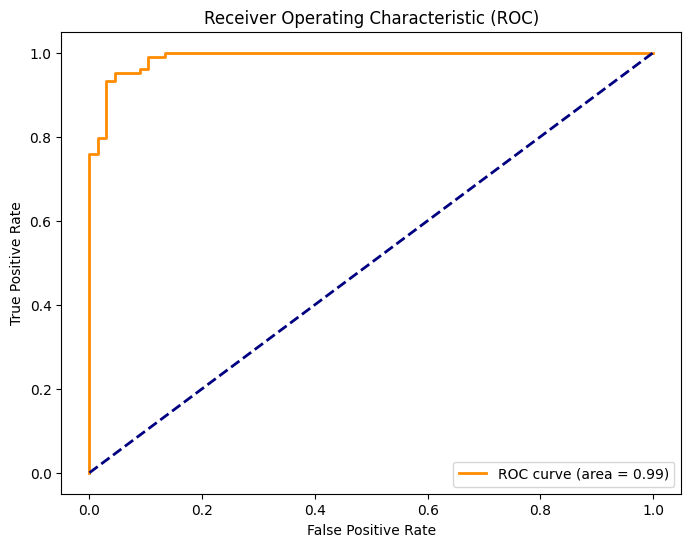

In [28]:
# Kurva ROC dengan diagonal classifier acak sebagai acuan
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Interpretasi output.** Kurva ROC naik hampir vertikal. *True positive rate* sudah mencapai sekitar 0,76 pada *false positive rate* 0, dan sekitar 0,95 pada FPR ≈ 0,05. Kurva mencapai 1,0 pada FPR ≈ 0,13, menempel di pojok kiri atas jauh di atas diagonal tebakan acak yang putus-putus. **AUC 0.99** berarti pada 99 % pasangan (jinak, ganas), model memberi peluang lebih tinggi pada tumor jinak. Jadi kualitas pemeringkatannya sangat baik, dan 11 kesalahan pada ambang default 0,5 sebagian besar berasal dari *letak* ambang tersebut. Menurunkan peluang yang dibutuhkan untuk menyebut tumor jinak akan menukar *recall* ganas dengan *recall* jinak, dan kurva ROC menunjukkan seluruh pilihan *trade-off* semacam itu.

### Poin Penting
* *Precision*, *recall*, dan F1 menggambarkan kelas positif (di sini jinak) pada ambang tetap. Kurva ROC dan AUC meringkas kualitas pemeringkatan di semua ambang.
* AUC 0,99 dengan akurasi 0,94 berarti skornya memeringkat hampir sempurna, dan kesalahan yang tersisa adalah soal pilihan ambang.
* Selalu periksa kelas mana yang "positif", karena kelas yang relevan secara klinis (ganas) adalah kelas 0 di sini.

## Resep 6.6 — Latihan Praktis Regresi Logistik Lanjutan

**Tujuan.** (1) Mem-fit regresi logistik dengan regularisasi L1 pada data Breast Cancer. (2) Mem-fit model multinomial pada Iris. (3) Memvisualisasikan batas keputusan regresi logistik pada dataset sintetis 2-D.

### Teori

* **Latihan 1** mengulang model L1 dari Resep 6.3 dengan $C=0.1$, tetapi **tanpa penskalaan** (dan dengan `max_iter=10000`). Karena penalti L1 memperlakukan setiap koefisien secara setara, fitur bersatuan besar hanya membutuhkan koefisien kecil dan lebih sedikit dikenai penalti. Akibatnya fitur yang terpilih bergantung pada satuan. (Judul latihan di buku menyebut "Ridge", tetapi kodenya mem-fit model L1/Lasso.)
* **Latihan 2** persis sama dengan model multinomial di Resep 6.2 (`lbfgs`, pembagian data yang sama), sehingga hasilnya seharusnya cocok.
* **Latihan 3** menunjukkan geometri dari Resep 6.1. Dengan dua fitur, batas keputusan $\beta_0+\beta_1x_1+\beta_2x_2=0$ adalah garis lurus, $x_2=-(\beta_0+\beta_1x_1)/\beta_2$. `make_classification(n_features=2, n_informative=2, n_redundant=0)` secara default membuat dua klaster Gaussian per kelas (`n_clusters_per_class=2`), yang hanya dapat dipisahkan sebagian oleh satu garis. Plot mengevaluasi `predict` pada grid titik yang rapat dan mewarnai grid berdasarkan kelas prediksi.

### Kode — Latihan 1: Model teregularisasi L1 pada Breast Cancer

In [29]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import pandas as pd

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Penalti L1 (C = 0.1) pada fitur mentah yang tidak diskalakan
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=10000, C=0.1)
lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)

accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
print(f"Lasso Model Accuracy: {accuracy_lasso:.2f}")

Lasso Model Accuracy: 0.95


In [30]:
# Fitur mana yang bertahan dari penalti L1 tanpa penskalaan? (tambahan)
nz = lasso_model.coef_[0] != 0
print("koefisien tak-nol:", int(nz.sum()), "dari 30")
print(pd.Series(lasso_model.coef_[0][nz], index=data.feature_names[nz]).round(4).to_string())

koefisien tak-nol: 7 dari 30
mean perimeter     0.2932
mean area          0.0014
area error        -0.0342
worst radius       0.5359
worst texture     -0.1052
worst perimeter   -0.1342
worst area        -0.0224


**Interpretasi output.** Model L1 tanpa penskalaan mencapai **akurasi 0.95** pada 171 tumor uji, di antara model L1 terskala (0.965) dan model default tanpa penskalaan di Resep 6.5 (0.94). Pengecekan tambahan menunjukkan model ini juga mempertahankan **7 dari 30** fitur, tetapi himpunannya berbeda: sebagian besar pengukuran **ukuran** mentah (`mean perimeter`, `mean area`, `area error`, `worst perimeter`, `worst area`) ditambah `worst radius` dan `worst texture`. Hanya `worst radius` dan `worst texture` yang beririsan dengan seleksi L1 terskala di Resep 6.3. Fitur bersatuan besar dapat bekerja melalui koefisien yang sangat kecil (`mean area` 0.0014, `worst area` −0.0224, karena area bernilai ratusan hingga ribuan), sehingga penalti L1 hampir tidak membebaninya. Seleksinya karena itu mencerminkan *satuan* sama besarnya dengan tingkat kepentingan. Beberapa tanda juga berlawanan dengan intuisi (`mean perimeter` dan `worst radius` positif di samping `worst perimeter` negatif), pola saling meniadakan yang khas pada fitur ukuran yang sangat berkorelasi. Ini alasan lain untuk melakukan standardisasi sebelum memakai L1 untuk seleksi fitur.

### Kode — Latihan 2: Mengevaluasi Regresi Logistik Multikelas

In [31]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Model softmax (multinomial), seperti di Resep 6.2
multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

y_pred_multinomial = multinomial_model.predict(X_test)

accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
print(f"Multinomial Model Accuracy: {accuracy_multinomial:.2f}")

Multinomial Model Accuracy: 0.93


**Interpretasi output.** Akurasinya **0.93**, identik dengan model multinomial di Resep 6.2 (42/45). Data, pembagian, solver, dan pengaturan yang sama menghasilkan fit deterministik yang sama. Solver `lbfgs` dengan penalti L2 memiliki optimum yang unik, sehingga tidak ada keacakan yang dapat mengubah hasil.

### Kode — Latihan 3: Memvisualisasikan Hasil Regresi Logistik

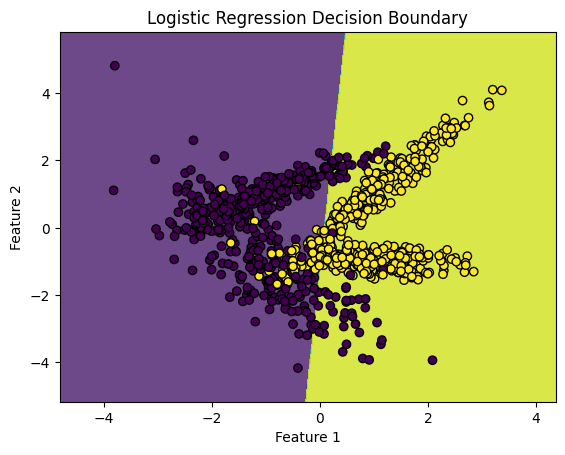

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Masalah biner 2-D (secara default dua klaster Gaussian per kelas)
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2, n_redundant=0, random_state=2024)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

# Grid rapat yang mencakup rentang data (langkah 0.01)
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Kelas prediksi untuk setiap titik grid
Z = logistic_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Wilayah berwarna = kelas prediksi; titik = seluruh 1.000 sampel
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [33]:
# Akurasi uji dan garis hasil fit (tambahan)
b0, (b1, b2) = logistic_model.intercept_[0], logistic_model.coef_[0]
print(f"akurasi uji: {logistic_model.score(X_test, y_test):.3f}")
print(f"batas: {b0:.3f} + {b1:.3f}*x1 + {b2:.3f}*x2 = 0  ->  x1 = {-b0/b1:.3f} + {-b2/b1:.3f}*x2")

akurasi uji: 0.897
batas: -0.183 + 2.283*x1 + -0.154*x2 = 0  ->  x1 = 0.080 + 0.068*x2


**Interpretasi output.** Batasnya berupa **garis lurus yang hampir vertikal** di dekat $x_1\approx0$. Pengecekan tambahan memberikan persamaannya: koefisien Feature 1 (≈ 2,28) jauh lebih besar daripada koefisien Feature 2 (≈ −0,15), sehingga model pada dasarnya memakai ambang pada Feature 1. Kelas kuning terdiri atas dua klaster memanjang di sebelah kanan, dan kelas ungu tersebar di kiri. Titik-titik dari kedua kelas melintasi garis di dekat tengah, tempat klaster-klaster bertumpang tindih, dan model linear tidak dapat melengkung mengitarinya. Akurasi ujinya **0.897**. Menangkap struktur yang tersisa memerlukan fitur non-linear atau model non-linear seperti SVM dengan kernel di Bab 7.

### Poin Penting
* Seleksi L1 pada data yang tidak diskalakan bergantung pada satuan fitur. Lakukan standardisasi lebih dulu jika ingin seleksi berdasarkan tingkat kepentingan.
* Data, pembagian, dan solver yang identik memberi hasil identik (0.93 di Latihan 2 dan Resep 6.2).
* Dengan dua fitur, batas logistik adalah garis lurus. Di sini akurasinya 0.897 dan tidak dapat memisahkan kelas yang bertumpang tindih dan terdiri atas beberapa klaster.

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 6.1 Gambaran Regresi Logistik | Sigmoid dari skor linear = peluang; fitting dengan log-loss | `LogisticRegression`, `confusion_matrix` | 94,7 % pada Breast Cancer, 2 tumor ganas terlewat. Data tanpa penskalaan membutuhkan lebih dari 2.000 iterasi lbfgs. |
| 6.2 Teknik Multikelas | *One-vs-rest* vs multinomial (softmax) | `LogisticRegression(solver="liblinear" / "lbfgs")` | OvR 0.956 vs multinomial 0.933 (selisih satu bunga). Kesalahan hanya versicolor ↔ virginica. |
| 6.3 Regularisasi | Penalti L1/L2 yang dikendalikan kebalikan kekuatan `C` | `penalty`, `C`, `solver="liblinear"` | L2 0.982. L1 0.965 dengan 7/30 fitur. Jalur L1 menambah fitur seiring bertambahnya `C`. |
| 6.4 Klasifikasi Multilabel | *Binary relevance*, *subset accuracy*, Hamming loss, ko-okurensi | `make_multilabel_classification`, `LogisticRegression` per label | F1 micro 0,70 tetapi *subset accuracy* 0,34. Label yang jarang kurang diprediksi, dan ketergantungan antarlabel yang kuat diabaikan. |
| 6.5 Metrik Evaluasi | *Precision*, *recall*, F1, kurva ROC, AUC | `precision_score`, `recall_score`, `f1_score`, `roc_curve`, `auc` | AUC 0,99 vs akurasi 0,94: pemeringkatan sangat baik, sehingga kesalahan yang tersisa soal pilihan ambang. |
| 6.6 Latihan Praktis | L1 tanpa penskalaan, multinomial, batas keputusan 2-D | `LogisticRegression`, `make_classification` | Seleksi L1 tanpa penskalaan bergantung pada satuan. Batas linear mencapai 0,897 pada data 2-D berklaster banyak. |

**Kaitan dengan Bab 7.** Regresi logistik menarik satu batas linear dan di-fit dengan memaksimalkan *likelihood* atas *semua* titik. **Support vector machine** (Bab 7) juga berangkat dari batas linear, tetapi memilih batas dengan **margin terlebar**, yang hanya ditentukan oleh titik-titik terdekat dengannya (*support vector*). Melalui **kernel trick**, SVM dapat melengkungkan batas itu, yang menjawab persis keterbatasan yang terlihat di Latihan 3. Perangkat *precision/recall/ROC* dari Resep 6.5 dipakai lagi untuk mengevaluasinya.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 6.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Logistic regression (solver, penalti, kasus multinomial): <https://scikit-learn.org/1.5/modules/linear_model.html#logistic-regression>
* scikit-learn User Guide — Multiclass and multioutput algorithms: <https://scikit-learn.org/1.5/modules/multiclass.html>
* scikit-learn User Guide — Classification metrics (precision/recall, ROC, metrik multilabel): <https://scikit-learn.org/1.5/modules/model_evaluation.html#classification-metrics>
* scikit-learn API — `make_multilabel_classification`: <https://scikit-learn.org/1.5/modules/generated/sklearn.datasets.make_multilabel_classification.html>
* Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27(8), 861–874.